# Decoding natural images from mouse visual cortex

Data: [Allen Brain Observatory, Visual Coding–Neuropixels](https://portal.brain-map.org/explore/circuits/visual-coding-neuropixels) (CC BY 4.0).

In [1]:
import subprocess
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import torch
import torchvision.models as tvm
import torchvision.transforms as T
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

S3 = ('https://allen-brain-observatory.s3.us-west-2.amazonaws.com'
      '/visual-coding-neuropixels/ecephys-cache')
DATA, CACHE, FIGS = Path('data'), Path('cache'), Path('figures')
for d in (DATA, CACHE, FIGS):
    d.mkdir(exist_ok=True)

DEVICE = ('cuda' if torch.cuda.is_available()
          else 'mps' if torch.backends.mps.is_available() else 'cpu')
N_IMAGES = 118
WINDOW = (0.030, 0.250)   # s after stimulus onset; skip the first 30 ms of transit
torch.manual_seed(0)
RNG = np.random.RandomState(0)

## Picking sessions

In [2]:
def fetch(url, path, expect_size=None):
    path = Path(path)
    for _ in range(3):
        if path.exists() and (expect_size is None or path.stat().st_size == expect_size):
            return path
        subprocess.run(['curl', '-sL', '-C', '-', url, '-o', str(path)], check=True)
    raise RuntimeError(f'could not download {url}')


def remote_size(url):
    head = subprocess.run(['curl', '-sI', url], capture_output=True, text=True).stdout
    lengths = [l.split()[1] for l in head.splitlines() if l.lower().startswith('content-length')]
    return int(lengths[-1]) if lengths else None

In [3]:
for name in ['sessions.csv', 'probes.csv', 'channels.csv', 'units.csv']:
    fetch(f'{S3}/{name}', DATA / name)

sessions = pd.read_csv(DATA / 'sessions.csv')
probes   = pd.read_csv(DATA / 'probes.csv')
channels = pd.read_csv(DATA / 'channels.csv')
units    = pd.read_csv(DATA / 'units.csv', low_memory=False)

units = (units
         .merge(channels[['id', 'ecephys_probe_id', 'ecephys_structure_acronym']]
                .rename(columns={'id': 'ecephys_channel_id'}), on='ecephys_channel_id')
         .merge(probes[['id', 'ecephys_session_id']]
                .rename(columns={'id': 'ecephys_probe_id'}), on='ecephys_probe_id')
         .merge(sessions[['id', 'session_type']]
                .rename(columns={'id': 'ecephys_session_id'}), on='ecephys_session_id'))

visual = units[units.ecephys_structure_acronym.astype(str).str.startswith('VIS')
               & (units.session_type == 'brain_observatory_1.1')]
good = visual.query('snr > 1 and isi_violations < 0.5 '
                    'and amplitude_cutoff < 0.1 and presence_ratio > 0.9')

ranked = good.groupby('ecephys_session_id').size().sort_values(ascending=False)
SESSION_IDS = ranked.head(8).index.tolist()
print(f'{len(good)} usable neurons in {ranked.size} sessions; taking the top 8')
ranked.head(8)

9620 usable neurons in 32 sessions; taking the top 8


ecephys_session_id
798911424    471
760693773    428
761418226    399
757216464    368
755434585    364
742951821    357
732592105    353
762602078    351
dtype: int64

## Spike counts

In [4]:
def extract_session(sid):
    # ~2.9 GB in, ~9 MB out, raw file deleted before the next one downloads
    url = f'{S3}/session_{sid}/session_{sid}.nwb'
    raw = fetch(url, DATA / f'session_{sid}.nwb', expect_size=remote_size(url))

    with h5py.File(raw, 'r') as f:
        electrodes = f['general/extracellular_ephys/electrodes']
        area_of = pd.Series([s.decode() for s in electrodes['location'][:]],
                            index=electrodes['id'][:])

        u = f['units']
        quality = np.array([s.decode() for s in u['quality'][:]])
        area = np.array([str(a) for a in area_of.reindex(u['peak_channel_id'][:])], dtype='<U16')
        keep = np.flatnonzero((quality == 'good')
                              & (u['snr'][:] > 1)
                              & (u['isi_violations'][:] < 0.5)
                              & (u['amplitude_cutoff'][:] < 0.1)
                              & (u['presence_ratio'][:] > 0.9)
                              & np.char.startswith(area, 'VIS'))

        trials = f['intervals/natural_scenes_presentations']
        frame, onset = trials['frame'][:], trials['start_time'][:]
        shown = frame >= 0                       # -1 marks blank-screen trials
        frame, onset = frame[shown].astype(int), onset[shown]

        spikes, ends = u['spike_times'], np.concatenate([[0], u['spike_times_index'][:]])
        counts = np.empty((onset.size, keep.size), np.float32)
        for col, i in enumerate(keep):
            t = spikes[ends[i]:ends[i + 1]]      # this neuron's spike times, already sorted
            counts[:, col] = (np.searchsorted(t, onset + WINDOW[1])
                              - np.searchsorted(t, onset + WINDOW[0]))

        unit_id = u['id'][:][keep]

    raw.unlink()
    return dict(counts=counts, frame=frame, unit_id=unit_id, area=area[keep])


for sid in SESSION_IDS:
    out = CACHE / f'session_{sid}.npz'
    if out.exists():
        continue
    np.savez_compressed(out, **extract_session(sid))
    print(sid, 'done')

recordings = [np.load(CACHE / f'session_{sid}.npz') for sid in SESSION_IDS]
for sid, r in zip(SESSION_IDS, recordings):
    rate = r['counts'].mean() / (WINDOW[1] - WINDOW[0])
    print(f'{sid}: {r["counts"].shape[1]:3d} neurons, {r["counts"].shape[0]} trials, {rate:.1f} Hz')

798911424: 447 neurons, 5900 trials, 6.2 Hz
760693773: 411 neurons, 5900 trials, 6.7 Hz
761418226: 377 neurons, 5900 trials, 8.6 Hz
757216464: 354 neurons, 5900 trials, 6.4 Hz
755434585: 346 neurons, 5900 trials, 7.3 Hz
742951821: 343 neurons, 5900 trials, 5.8 Hz
732592105: 352 neurons, 5900 trials, 6.9 Hz
762602078: 338 neurons, 5900 trials, 7.3 Hz


## One pseudo-population

In [5]:
def pseudo_population(recordings):
    # same 118 images in every mouse, so pair trials across animals.
    # not simultaneously recorded: nothing here can speak to neuron-neuron correlations.
    trials_for = [{i: np.flatnonzero(r['frame'] == i) for i in range(N_IMAGES)}
                  for r in recordings]
    X, y = [], []
    for i in range(N_IMAGES):
        n = min(len(t[i]) for t in trials_for)
        picks = [RNG.permutation(t[i])[:n] for t in trials_for]
        X.append(np.hstack([r['counts'][p] for r, p in zip(recordings, picks)]))
        y.append(np.full(n, i))
    return np.vstack(X), np.concatenate(y)


X, y = pseudo_population(recordings)
X = np.sqrt(X)        # counts are Poisson-ish; sqrt stabilises the variance
print(X.shape, '(trials x neurons)')

(5900, 2968) (trials x neurons)


## Five descriptions of each image

In [6]:
scene_paths = sorted((DATA / 'scenes').glob('*.tiff'),
                     key=lambda p: int(p.stem.split('_')[-1]))   # numeric, not lexical
scenes = [Image.open(p) for p in scene_paths]
assert len(scenes) == N_IMAGES

if not (CACHE / 'img_features.npz').exists():
    import open_clip

    resnet = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1).eval().to(DEVICE)
    prep = T.Compose([T.Resize((224, 224)), T.Grayscale(3), T.ToTensor(),
                      T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    with torch.no_grad():
        x = torch.stack([prep(im) for im in scenes]).to(DEVICE)
        h = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
        blocks = {}
        for name, layer in [('early', resnet.layer1), ('mid', resnet.layer2), ('late', resnet.layer3)]:
            h = layer(h)
            pooled = torch.nn.functional.adaptive_avg_pool2d(h.cpu(), 4)
            blocks[name] = pooled.flatten(1).numpy()

    clip_model, _, clip_prep = open_clip.create_model_and_transforms(
        'ViT-B-32', pretrained='laion2b_s34b_b79k')
    clip_model = clip_model.eval().to(DEVICE)
    with torch.no_grad():
        x = torch.stack([clip_prep(im.convert('RGB')) for im in scenes]).to(DEVICE)
        emb = clip_model.encode_image(x)
        clip = (emb / emb.norm(dim=-1, keepdim=True)).cpu().numpy()

    pixels = np.stack([np.asarray(im.resize((80, 64)), np.float32).ravel() / 255 for im in scenes])
    np.savez(CACHE / 'img_features.npz', pixels=pixels, clip=clip, **blocks)

features = dict(np.load(CACHE / 'img_features.npz'))
{k: v.shape for k, v in features.items()}

{'pixels': (118, 5120),
 'early': (118, 1024),
 'mid': (118, 2048),
 'late': (118, 4096),
 'clip': (118, 512)}

## Decoding

In [7]:
def unit_norm(M):
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)


def decode(target, train_img, test_img, alpha=1e3, neurons=None):
    train = np.isin(y, train_img)
    test = np.isin(y, test_img)
    Z = X[:, neurons] if neurons is not None else X

    mu, sd = Z[train].mean(0), Z[train].std(0) + 1e-6          # training rows only
    f_mu, f_sd = target[train_img].mean(0), target[train_img].std(0) + 1e-6   # training images only
    model = Ridge(alpha=alpha).fit((Z[train] - mu) / sd, (target[y[train]] - f_mu) / f_sd)

    held = (Z[test] - mu) / sd
    averaged = np.stack([held[y[test] == i].mean(0) for i in test_img])
    return model.predict(averaged), (target - f_mu) / f_sd


def identification(target, alpha=1e3, neurons=None, n_folds=6):
    """Fraction of held-out images correctly identified, within the fold and against all 118."""
    within, overall = [], []
    for train_img, test_img in KFold(n_folds, shuffle=True, random_state=0).split(np.arange(N_IMAGES)):
        pred, scaled = decode(target, train_img, test_img, alpha, neurons)
        pred, scaled = unit_norm(pred), unit_norm(scaled)
        within.append(((pred @ scaled[test_img].T).argmax(1) == np.arange(test_img.size)).mean())
        overall.append(np.mean([(p @ scaled.T).argmax() == i for p, i in zip(pred, test_img)]))
    return np.mean(within), np.mean(overall)

In [8]:
ALPHAS = [1e3, 1e4, 3e4, 1e5]
scores = {}
for name, target in features.items():
    scores[name] = max((identification(target, a) for a in ALPHAS), key=lambda s: s[0])

table = (pd.DataFrame(scores, index=['held_out_20', 'all_118']).T
           .loc[['pixels', 'early', 'mid', 'late', 'clip']])
table.round(3)

,held_out_20,all_118
pixels,0.822,0.341
early,0.874,0.279
mid,0.795,0.085
late,0.736,0.000
clip,0.271,0.034


Chance is 0.050 and 0.008 respectively.

## Figures

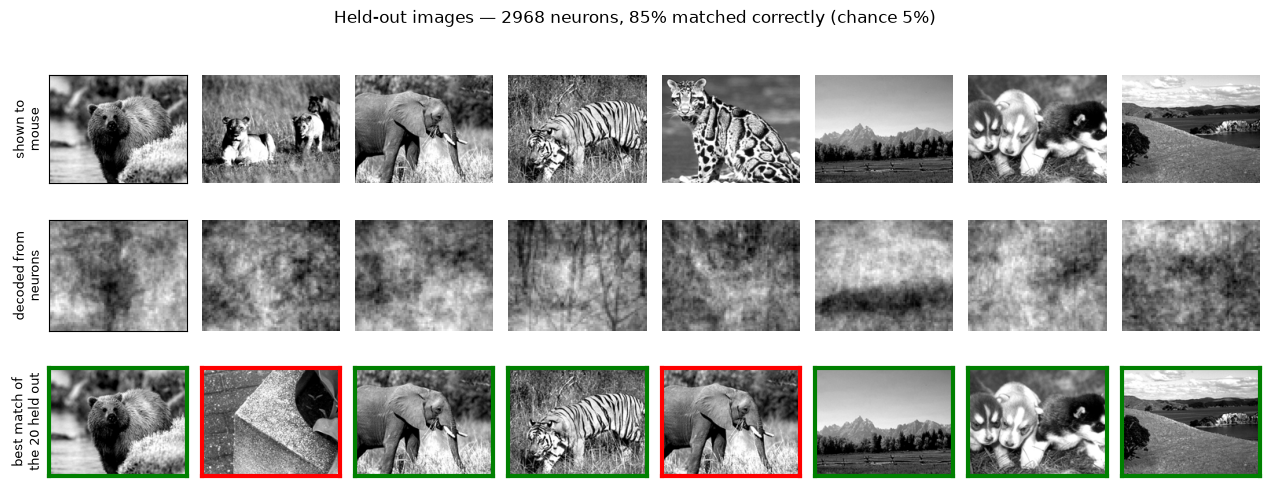

In [9]:
thumbs = np.stack([np.asarray(im.resize((176, 138))) for im in scenes])
train_img, test_img = next(iter(KFold(6, shuffle=True, random_state=0).split(np.arange(N_IMAGES))))
pred, scaled = decode(features['pixels'], train_img, test_img)
match = (unit_norm(pred) @ unit_norm(scaled[test_img]).T).argmax(1)
accuracy = (match == np.arange(test_img.size)).mean()

n = 8
fig, axes = plt.subplots(3, n, figsize=(1.6 * n, 5.2))
for k in range(n):
    axes[0, k].imshow(thumbs[test_img[k]], cmap='gray')
    axes[1, k].imshow(pred[k].reshape(64, 80), cmap='gray')
    axes[2, k].imshow(thumbs[test_img[match[k]]], cmap='gray')
    for spine in axes[2, k].spines.values():
        spine.set_color('green' if match[k] == k else 'red')
        spine.set_linewidth(3)
    axes[2, k].set_xticks([]); axes[2, k].set_yticks([])
    axes[0, k].axis('off'); axes[1, k].axis('off')
for row, label in enumerate(['shown to\nmouse', 'decoded from\nneurons', 'best match of\nthe 20 held out']):
    axes[row, 0].set_ylabel(label, fontsize=9)
    axes[row, 0].axis('on'); axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
fig.suptitle(f'Held-out images — {X.shape[1]} neurons, '
             f'{accuracy:.0%} matched correctly (chance 5%)')
fig.tight_layout()
fig.savefig(FIGS / 'retrieval.png', dpi=150, bbox_inches='tight')

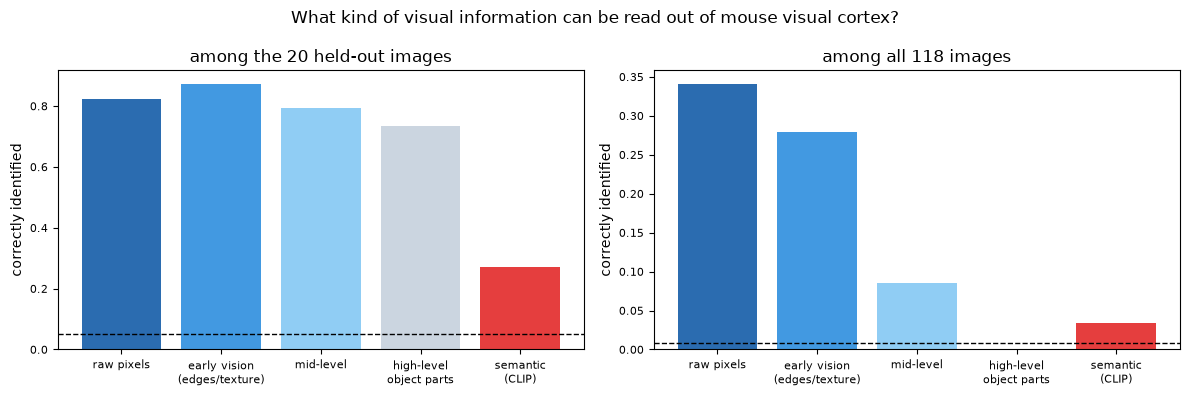

In [10]:
labels = ['raw pixels', 'early vision\n(edges/texture)', 'mid-level',
          'high-level\nobject parts', 'semantic\n(CLIP)']
colors = ['#2b6cb0', '#4299e1', '#90cdf4', '#cbd5e0', '#e53e3e']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title, chance in [(axes[0], 'held_out_20', 'among the 20 held-out images', 1 / 20),
                               (axes[1], 'all_118', 'among all 118 images', 1 / N_IMAGES)]:
    ax.bar(labels, table[col], color=colors)
    ax.axhline(chance, ls='--', c='k', lw=1)
    ax.set_title(title); ax.set_ylabel('correctly identified'); ax.tick_params(labelsize=8)
fig.suptitle('What kind of visual information can be read out of mouse visual cortex?')
fig.tight_layout()
fig.savefig(FIGS / 'feature_spaces.png', dpi=150, bbox_inches='tight')

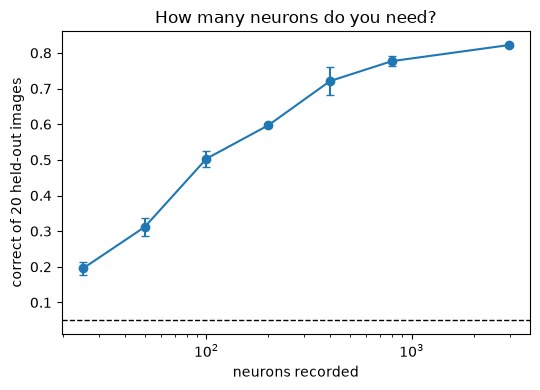

In [11]:
sizes = [25, 50, 100, 200, 400, 800, X.shape[1]]
curve = np.array([[identification(features['pixels'],
                                  neurons=RNG.choice(X.shape[1], s, replace=False))[0]
                   for _ in range(3)] for s in sizes])

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.errorbar(sizes, curve.mean(1), yerr=curve.std(1), marker='o', capsize=3)
ax.axhline(1 / 20, ls='--', c='k', lw=1)
ax.set_xscale('log')
ax.set_xlabel('neurons recorded'); ax.set_ylabel('correct of 20 held-out images')
ax.set_title('How many neurons do you need?')
fig.tight_layout()
fig.savefig(FIGS / 'neuron_scaling.png', dpi=150, bbox_inches='tight')

## Result

Accuracy falls steadily as the target description becomes more semantic, and CLIP lands near
chance on the 118-way test. The CLIP-reconstruction recipe used for human fMRI does not
transfer here: what this cortex encodes about these photographs is close to the image itself,
not its meaning.